# 04 - Clusterización (K-Means)
Proyecto Final de Minería de Datos
Análisis de la intención de compra en comercio electrónico (Online Shoppers Purchasing Intention Dataset, UCI)

Responsable: (completar)

## Objetivo

Identificar **grupos de sesiones con comportamiento de navegación similar**, determinar un número adecuado de clústeres e interpretar los resultados. Se usa K-Means sobre variables de comportamiento (páginas visitadas, tiempo por tipo de página y tasas de rebote y salida).

## Acuerdos del equipo que se respetan

- Se lee `data/datos_limpios.csv` (sin escalar). No se vuelve a limpiar nada.
- Se usa la partición de la columna `conjunto` (`train` 80 % / `test` 20 %, `random_state=42`). `conjunto` no es una característica.
- El escalador se ajusta **solo con `train`** y se aplica a `test`.
- `Revenue` **no se usa para agrupar**; solo se usa después para describir los clústeres.
- Los outliers no se eliminaron en el preprocesamiento; aquí se manejan con una transformación (`log1p`), no borrando sesiones.

## Contenido

1. Carga de datos
2. Selección de variables
3. Preparación: transformación y escalado
4. Elección del número de clústeres (k)
5. Modelo final
6. Evaluación del modelo
7. Visualización en 2D (PCA)
8. Interpretación de los clústeres
9. Hallazgos, limitaciones y exportación

## 0. Configuración

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy.stats import chi2_contingency
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (silhouette_score, silhouette_samples, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score)

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

# Parámetros del proyecto (no cambiar sin avisar al equipo)
RANDOM_STATE = 42
RUTA_CSV = "data/datos_limpios.csv"
DIR_FIG = "figuras"

# Parámetros de esta sección
K_RANGO = range(2, 11)   # valores de k que se comparan
K_FINAL = 5              # k elegido (se justifica en la sección 4)
N_INIT = 50              # inicializaciones del modelo final
os.makedirs(DIR_FIG, exist_ok=True)

# Estilo de las gráficas: fondo claro, ejes discretos, un solo color de acento
C = dict(fondo="#fcfcfb", tinta="#0b0b0b", tinta2="#52514e", rejilla="#e4e3de",
         gris="#c9c8c2", azul="#2a78d6", naranja="#eb6834", neutro="#ecebe6")
plt.rcParams.update({
    "figure.facecolor": C["fondo"], "axes.facecolor": C["fondo"], "savefig.facecolor": C["fondo"],
    "axes.edgecolor": C["rejilla"], "axes.labelcolor": C["tinta2"], "text.color": C["tinta"],
    "xtick.color": C["tinta2"], "ytick.color": C["tinta2"],
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": C["rejilla"], "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "font.size": 10, "lines.linewidth": 2,
})
CMAP_DIV = LinearSegmentedColormap.from_list("div", [C["naranja"], C["neutro"], C["azul"]])
CMAP_SEC = LinearSegmentedColormap.from_list("sec", [C["fondo"], C["azul"]])

def guardar(nombre):
    plt.savefig(f"{DIR_FIG}/{nombre}", dpi=150, bbox_inches="tight")

## 1. Carga de datos

In [2]:
df = pd.read_csv(RUTA_CSV)
train = df[df["conjunto"] == "train"].copy()
test = df[df["conjunto"] == "test"].copy()

print("Filas, columnas:", df.shape)
print(f"Partición: {len(train)} train / {len(test)} test")
print(f"Tasa de compra: train {train['Revenue'].mean():.4f} | test {test['Revenue'].mean():.4f}")
df.head()

Filas, columnas: (12205, 26)
Partición: 9764 train / 2441 test
Tasa de compra: train 0.1563 | test 0.1565


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue,TotalPages,NonProductDuration,ProductPageRatio,TotalDuration,AvgTimePerPage,IsSpecialDay,HasPageValue,conjunto
0,0,0.000,0,0.000,1,0.000,0.200,0.200,0.000,0.000,Feb,1,1,1,1,Returning_Visitor,0,0,1,0.000,1.000,0.000,0.000,0,0,train
1,0,0.000,0,0.000,2,64.000,0.000,0.100,0.000,0.000,Feb,2,2,1,2,Returning_Visitor,0,0,2,0.000,1.000,64.000,32.000,0,0,test
2,0,0.000,0,0.000,1,0.000,0.200,0.200,0.000,0.000,Feb,4,1,9,3,Returning_Visitor,0,0,1,0.000,1.000,0.000,0.000,0,0,train
3,0,0.000,0,0.000,2,2.667,0.050,0.140,0.000,0.000,Feb,3,2,2,4,Returning_Visitor,0,0,2,0.000,1.000,2.667,1.333,0,0,train
4,0,0.000,0,0.000,10,627.500,0.020,0.050,0.000,0.000,Feb,3,3,1,4,Returning_Visitor,1,0,10,0.000,1.000,627.500,62.750,0,0,test


## 2. Selección de variables

K-Means usa distancia euclidiana, así que solo tiene sentido con variables numéricas que describan **comportamiento de navegación**. Se usan las 6 variables que propuso el notebook de preprocesamiento:

| Variable | Qué mide |
|---|---|
| `Administrative_Duration` | segundos en páginas administrativas (cuenta, pedidos) |
| `Informational_Duration` | segundos en páginas informativas (contacto, ayuda) |
| `ProductRelated_Duration` | segundos en páginas de productos |
| `ProductRelated` | número de páginas de productos vistas |
| `BounceRates` | tasa de rebote promedio de las páginas visitadas |
| `ExitRates` | tasa de salida promedio de las páginas visitadas |

**Se dejan fuera a propósito:**
- `Revenue`: es el resultado que se quiere explicar; agrupar con él sería hacer trampa. Se usa solo para interpretar.
- `PageValues`: está muy ligada a `Revenue` (solo 22 % de las sesiones tienen valor > 0, pero ahí están 81 % de las compras). Se usa solo para interpretar.
- Variables derivadas (`TotalPages`, `TotalDuration`, `AvgTimePerPage`...): son combinaciones de las anteriores y meterían la misma información dos veces.
- Variables categóricas (`Month`, `VisitorType`, `Region`...): la distancia euclidiana no es adecuada para códigos nominales. También se usan solo para describir.

In [3]:
COLS_CLUSTER = ["Administrative_Duration", "Informational_Duration", "ProductRelated_Duration",
                "ProductRelated", "BounceRates", "ExitRates"]

resumen = pd.DataFrame({
    "% de ceros": (train[COLS_CLUSTER] == 0).mean() * 100,
    "mediana": train[COLS_CLUSTER].median(),
    "máximo": train[COLS_CLUSTER].max(),
    "asimetría": train[COLS_CLUSTER].skew(),
})
resumen

,% de ceros,mediana,máximo,asimetría
Administrative_Duration,47.368,9.000,"3,398.750",5.677
Informational_Duration,80.367,0.000,"2,549.375",7.543
ProductRelated_Duration,5.152,617.000,"63,973.522",7.872
ProductRelated,0.328,18.000,705.000,4.390
BounceRates,45.320,0.003,0.200,3.173
ExitRates,0.655,0.025,0.200,2.237


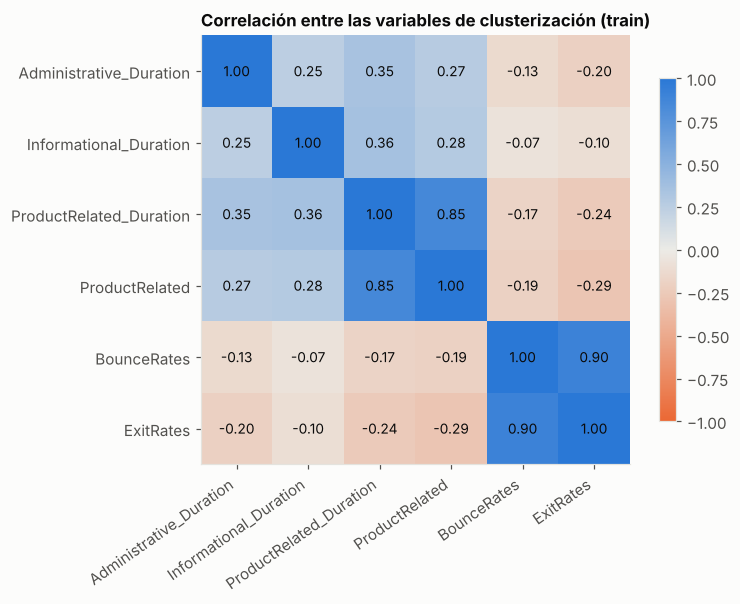

In [4]:
corr = train[COLS_CLUSTER].corr()

fig, ax = plt.subplots(figsize=(7.2, 5.6))
im = ax.imshow(corr, cmap=CMAP_DIV, vmin=-1, vmax=1)
ax.grid(False)
ax.set_xticks(range(len(COLS_CLUSTER)), COLS_CLUSTER, rotation=35, ha="right")
ax.set_yticks(range(len(COLS_CLUSTER)), COLS_CLUSTER)
for i in range(len(COLS_CLUSTER)):
    for j in range(len(COLS_CLUSTER)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", color=C["tinta"], fontsize=9)
ax.set_title("Correlación entre las variables de clusterización (train)")
fig.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout()
guardar("04_correlacion_variables.png")
plt.show()

**Observaciones**

- Hay mucha masa en cero: `Informational_Duration` es cero en ~80 % de las sesiones y `Administrative_Duration` en ~47 %. Además las variables de tiempo y de conteo tienen asimetría muy alta (hasta 7.9), con sesiones extremas de casi 64,000 segundos.
- `BounceRates` y `ExitRates` están muy correlacionadas (0.90) y `ProductRelated` con `ProductRelated_Duration` también (0.85). Esa redundancia hace que el comportamiento en productos y la salida pesen más en la distancia. En la sección 6 se comprueba que el resultado no depende de ella.

## 3. Preparación: transformación y escalado

Dos problemas para K-Means:

1. **Escala**: duraciones en segundos (hasta decenas de miles) frente a tasas entre 0 y 1. Sin escalar, mandan las duraciones.
2. **Colas largas**: como los outliers no se eliminaron (acuerdo del equipo), unas pocas sesiones extremas pueden formar clústeres propios y dejar al resto en un solo bloque.

Solución: `log1p` (que maneja bien los ceros) en las seis variables y después `StandardScaler` **ajustado solo con `train`**. En las tasas, que ya están en [0, 1], el efecto de `log1p` es leve; se aplica a todas por simplicidad y consistencia.

In [5]:
def transformar(d):
    return np.log1p(d[COLS_CLUSTER])

asimetria = pd.DataFrame({"antes (original)": train[COLS_CLUSTER].skew(),
                          "después (log1p)": transformar(train).skew()})
asimetria

,antes (original),después (log1p)
Administrative_Duration,5.677,0.240
Informational_Duration,7.543,1.913
ProductRelated_Duration,7.872,-1.431
ProductRelated,4.390,-0.043
BounceRates,3.173,3.089
ExitRates,2.237,2.132


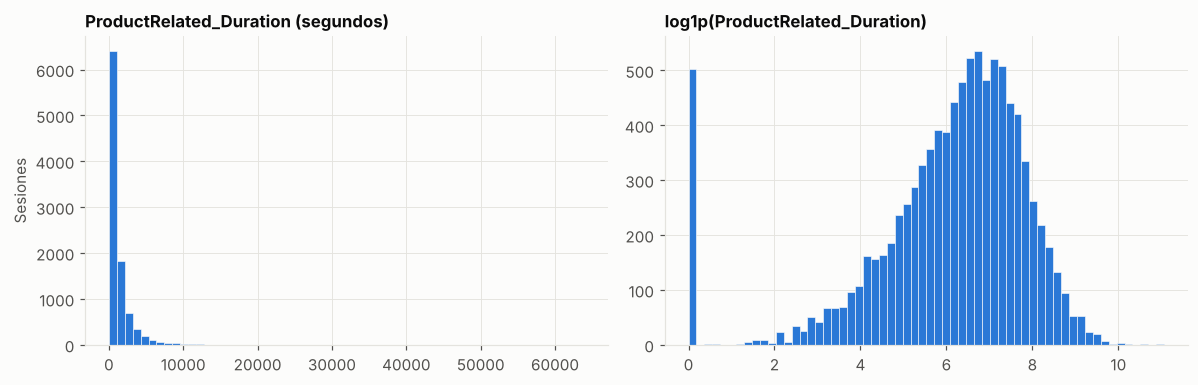

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].hist(train["ProductRelated_Duration"], bins=60, color=C["azul"], edgecolor=C["fondo"], linewidth=0.4)
axes[0].set_title("ProductRelated_Duration (segundos)")
axes[0].set_ylabel("Sesiones")
axes[1].hist(np.log1p(train["ProductRelated_Duration"]), bins=60, color=C["azul"], edgecolor=C["fondo"], linewidth=0.4)
axes[1].set_title("log1p(ProductRelated_Duration)")
plt.tight_layout()
guardar("04_efecto_log1p.png")
plt.show()

In [7]:
# Escalado: se ajusta solo con train y se aplica a test
scaler = StandardScaler().fit(transformar(train))
X_train = scaler.transform(transformar(train))
X_test = scaler.transform(transformar(test))
print("train:", X_train.shape, "| test:", X_test.shape)
print("Media de train escalado (≈0):", X_train.mean(axis=0).round(3))
print("Desv. est. de train escalado (≈1):", X_train.std(axis=0).round(3))

train: (9764, 6) | test: (2441, 6)
Media de train escalado (≈0): [ 0.  0. -0.  0.  0.  0.]
Desv. est. de train escalado (≈1): [1. 1. 1. 1. 1. 1.]


### 3.1 ¿Realmente hace falta `log1p`? Comparación con los datos sin transformar

Se corre K-Means con k = 2 a 10 sobre las variables **solo estandarizadas** (sin `log1p`) y sobre las transformadas, y se compara la silueta y el tamaño del clúster más pequeño.

In [8]:
def barrido(X, ks, n_init=20):
    filas = []
    for k in ks:
        km = KMeans(k, n_init=n_init, random_state=RANDOM_STATE).fit(X)
        filas.append({"k": k, "inercia": km.inertia_,
                      "silueta": silhouette_score(X, km.labels_),
                      "davies_bouldin": davies_bouldin_score(X, km.labels_),
                      "calinski_harabasz": calinski_harabasz_score(X, km.labels_),
                      "cluster_mas_chico": int(np.bincount(km.labels_).min())})
    return pd.DataFrame(filas).set_index("k")

# Sin log1p (solo estandarizado)
X_train_sin_log = StandardScaler().fit(train[COLS_CLUSTER]).transform(train[COLS_CLUSTER])
res_sin_log = barrido(X_train_sin_log, K_RANGO)

# Con log1p (propuesta)
res = barrido(X_train, K_RANGO)

comparacion = pd.concat({"sin log1p": res_sin_log[["silueta", "cluster_mas_chico"]],
                         "con log1p": res[["silueta", "cluster_mas_chico"]]}, axis=1)
comparacion

sin log1p                   con log1p                  
     silueta cluster_mas_chico   silueta cluster_mas_chico
k                                                         
2      0.599               730     0.578               717
3      0.616               716     0.333               631
4      0.581               137     0.360               607
5      0.588               129     0.360               559
6      0.459               132     0.346               546
7      0.386                91     0.346               480
8      0.386                 3     0.339               480
9      0.394                 3     0.318               481
10     0.361                 3     0.324               341

**Lectura.** Sin `log1p` la silueta parece buena (hasta 0.62 con k = 3), pero es engañosa: los clústeres pequeños son sesiones extremas (con k = 4 y 5 el más chico tiene ~130 sesiones y con k ≥ 8 aparecen clústeres de 3 sesiones). Con `log1p` los clústeres son más parejos (el más chico nunca baja de 341 sesiones) y la silueta es más baja pero honesta. Se continúa con `log1p`.

Nota: `log1p` corrige bien las duraciones y los conteos, pero casi no cambia las tasas (`BounceRates`, `ExitRates`), que siguen asimétricas, y deja a `ProductRelated_Duration` ligeramente sesgada hacia la izquierda (−1.4).

## 4. Elección del número de clústeres (k)

Se evalúan k = 2 a 10 con cuatro criterios, calculados sobre `train`:

- **Inercia (método del codo)**: suma de distancias al cuadrado a los centroides. Siempre baja al subir k; se busca el punto donde la mejora se aplana.
- **Silueta** (mayor es mejor): qué tan cerca está cada sesión de su clúster frente al más cercano.
- **Davies-Bouldin** (menor es mejor): separación entre clústeres.
- **Calinski-Harabasz** (mayor es mejor): cociente entre dispersión entre clústeres y dentro de ellos.

In [9]:
res

,inercia,silueta,davies_bouldin,calinski_harabasz,cluster_mas_chico
k,,,,,
2,"36,722.388",0.578,0.597,"5,811.524",717
3,"24,928.910",0.333,1.032,"6,588.914",631
4,"18,108.924",0.360,0.943,"7,271.493",607
5,"14,454.652",0.360,0.936,"7,448.444",559
6,"12,611.141",0.346,0.936,"7,114.424",546
7,"11,245.160",0.346,0.929,"6,845.709",480
8,"10,175.792",0.339,1.051,"6,630.175",480
9,"9,306.813",0.318,1.078,"6,456.325",481
10,"8,579.834",0.324,1.043,"6,316.421",341


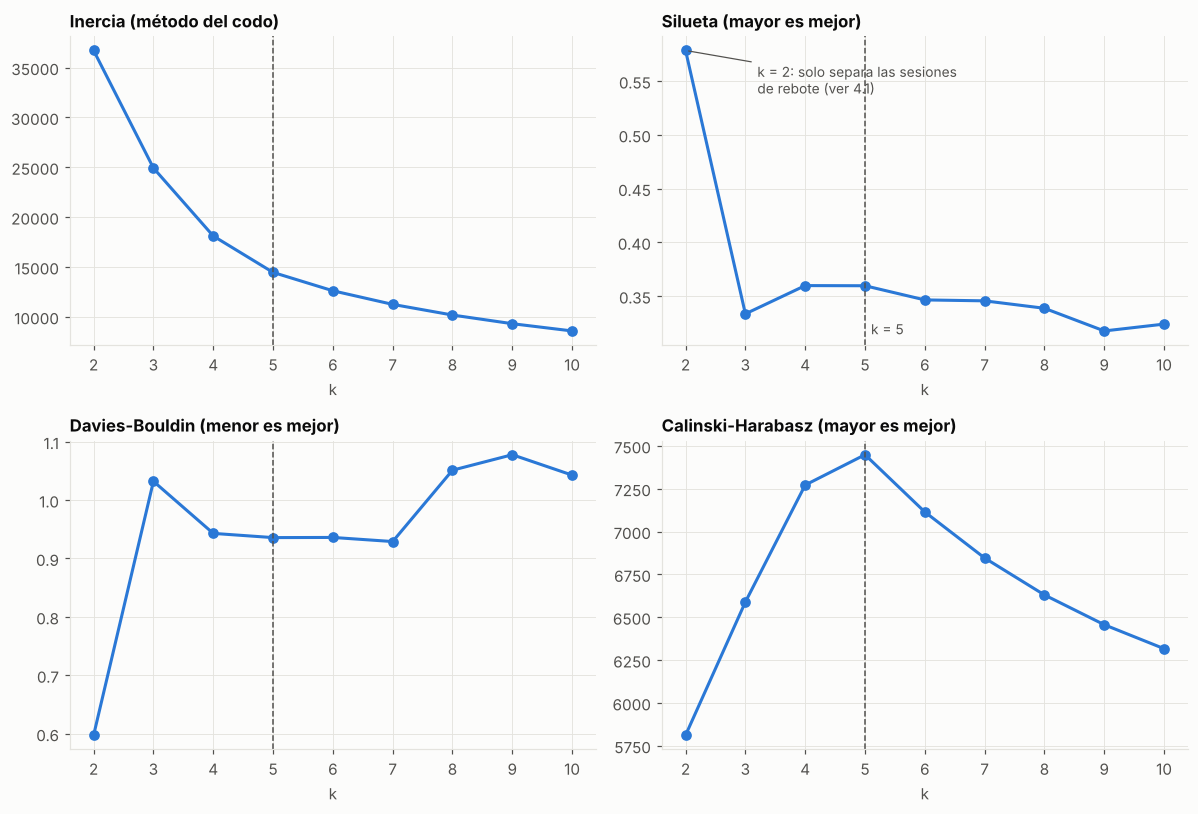

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7.5))
paneles = [("inercia", "Inercia (método del codo)"),
           ("silueta", "Silueta (mayor es mejor)"),
           ("davies_bouldin", "Davies-Bouldin (menor es mejor)"),
           ("calinski_harabasz", "Calinski-Harabasz (mayor es mejor)")]
for ax, (col, titulo) in zip(axes.ravel(), paneles):
    ax.plot(res.index, res[col], marker="o", markersize=6, color=C["azul"])
    ax.axvline(K_FINAL, color=C["tinta2"], linestyle="--", linewidth=1)
    ax.set_title(titulo)
    ax.set_xlabel("k")
    ax.set_xticks(list(K_RANGO))
axes[0, 1].annotate("k = 2: solo separa las sesiones\nde rebote (ver 4.1)", xy=(2, res.loc[2, "silueta"]),
                    xytext=(3.2, res.loc[2, "silueta"] - 0.04), fontsize=9, color=C["tinta2"],
                    arrowprops=dict(arrowstyle="-", color=C["tinta2"], lw=0.8))
axes[0, 1].text(K_FINAL + 0.1, axes[0, 1].get_ylim()[0] + 0.01, f"k = {K_FINAL}", color=C["tinta2"], fontsize=9)
plt.tight_layout()
guardar("04_seleccion_k.png")
plt.show()

In [11]:
# Mejor k por cada criterio, sin contar k = 2 (ver 4.1)
cand = res.loc[3:]
print("Mejor k (k >= 3) por silueta           :", cand["silueta"].idxmax())
print("Mejor k (k >= 3) por Davies-Bouldin    :", cand["davies_bouldin"].idxmin())
print("Mejor k (k >= 3) por Calinski-Harabasz :", cand["calinski_harabasz"].idxmax())

Mejor k (k >= 3) por silueta           : 4
Mejor k (k >= 3) por Davies-Bouldin    : 7
Mejor k (k >= 3) por Calinski-Harabasz : 5


### 4.1 Por qué no k = 2 aunque tenga la silueta más alta

Con k = 2 la silueta es la más alta, pero es un artefacto: el único corte que hace es separar un grupo pequeño de sesiones de rebote (una página vista y cero segundos) del resto. Es un hallazgo real, pero demasiado grueso para describir segmentos de clientes. La tabla de abajo lo confirma.

In [12]:
km2 = KMeans(2, n_init=20, random_state=RANDOM_STATE).fit(X_train)
perfil_k2 = train.assign(cluster=km2.labels_).groupby("cluster").agg(
    sesiones=("Revenue", "size"),
    paginas_producto_mediana=("ProductRelated", "median"),
    duracion_producto_mediana=("ProductRelated_Duration", "median"),
    rebote_medio=("BounceRates", "mean"),
    tasa_compra=("Revenue", "mean"))
perfil_k2

,sesiones,paginas_producto_mediana,duracion_producto_mediana,rebote_medio,tasa_compra
cluster,,,,,
0,9047,20.000,700.000,0.009,0.168
1,717,1.000,0.000,0.163,0.004


### 4.2 Decisión

Se elige **k = 5**. Es una decisión de criterio, porque ningún indicador la impone:

- **Calinski-Harabasz** es máximo en k = 5.
- **Silueta**: entre k ≥ 3, k = 4 y k = 5 empatan en 0.36 y son las más altas.
- **Davies-Bouldin** es casi plano entre k = 4 y k = 7 (0.93 a 0.94).
- **Codo**: no es marcado, pero la inercia deja de bajar rápido a partir de k = 5.
- **Tamaño**: con k = 5 el clúster más pequeño tiene 559 sesiones (5.7 %), así que ninguno es un grupo de outliers.
- **Interpretación**: k = 5 distingue visitas muy cortas (mediana de 95 s en productos) de visitas medianas de producto (710 s), que con k = 4 quedan mezcladas, y eso da una gradación más fina de la propensión a comprar (sección 8).

## 5. Modelo final

K-Means con k = 5, `n_init = 50` (se queda con la mejor de 50 inicializaciones) y `random_state = 42`.

Los números de clúster que asigna K-Means son arbitrarios y podrían cambiar entre versiones de scikit-learn. Para que los resultados sean reproducibles se **reordenan los clústeres de menor a mayor mediana de `TotalDuration`** (tiempo total en el sitio): el clúster 0 es el de menos actividad y el 4 el de más.

In [13]:
km = KMeans(K_FINAL, n_init=N_INIT, random_state=RANDOM_STATE).fit(X_train)

# Reordenar etiquetas: 0 = menos tiempo total en el sitio ... K-1 = más
orden = train.assign(c=km.labels_).groupby("c")["TotalDuration"].median().sort_values().index.to_numpy()
mapa = {viejo: nuevo for nuevo, viejo in enumerate(orden)}
centros = km.cluster_centers_[orden]             # centroides (espacio escalado), ya reordenados

def asignar(X):
    """Asigna sesiones (ya escaladas) al clúster más cercano, con etiquetas reordenadas."""
    return np.array([mapa[c] for c in km.predict(X)])

lab_train = asignar(X_train)
lab_test = asignar(X_test)
assert (lab_train == np.array([mapa[c] for c in km.labels_])).all()

train["cluster"], test["cluster"] = lab_train, lab_test
df_cl = pd.concat([train, test]).sort_index()    # todas las sesiones con su clúster

print(f"Inercia: {km.inertia_:,.1f} | iteraciones: {km.n_iter_}")
tamanos = pd.DataFrame({"train": pd.Series(lab_train).value_counts().sort_index(),
                        "test": pd.Series(lab_test).value_counts().sort_index()})
tamanos["% train"] = tamanos["train"] / tamanos["train"].sum() * 100
tamanos["% test"] = tamanos["test"] / tamanos["test"].sum() * 100
tamanos

Inercia: 14,454.7 | iteraciones: 6


,train,test,% train,% test
0,559,134,5.725,5.490
1,1881,463,19.265,18.968
2,2511,638,25.717,26.137
3,3160,795,32.364,32.569
4,1653,411,16.930,16.837


## 6. Evaluación del modelo

Como no hay etiquetas reales de clúster, la calidad se evalúa de cuatro formas:

1. Métricas internas (silueta, Davies-Bouldin, Calinski-Harabasz).
2. Silueta por clúster: ¿algún clúster está mal formado?
3. Estabilidad: ¿salen los mismos grupos con otras semillas?
4. Generalización: ¿las sesiones de `test`, que el modelo no vio, caen en los clústeres con proporciones y calidad parecidas?

In [14]:
sil_train = silhouette_score(X_train, lab_train)
sil_test = silhouette_score(X_test, lab_test)
metricas = pd.DataFrame({
    "train": [sil_train, davies_bouldin_score(X_train, lab_train), calinski_harabasz_score(X_train, lab_train)],
    "test (asignado al modelo de train)": [sil_test, davies_bouldin_score(X_test, lab_test), np.nan]},
    index=["Silueta", "Davies-Bouldin", "Calinski-Harabasz"])
metricas   # Calinski-Harabasz depende del tamaño de la muestra, por eso no se compara con test

,train,test (asignado al modelo de train)
Silueta,0.360,0.358
Davies-Bouldin,0.936,0.943
Calinski-Harabasz,"7,448.444",NaN


,silueta media,% de sesiones con silueta < 0
0,0.769,0.000
1,0.178,19.405
2,0.404,0.000
3,0.375,0.696
4,0.331,3.932


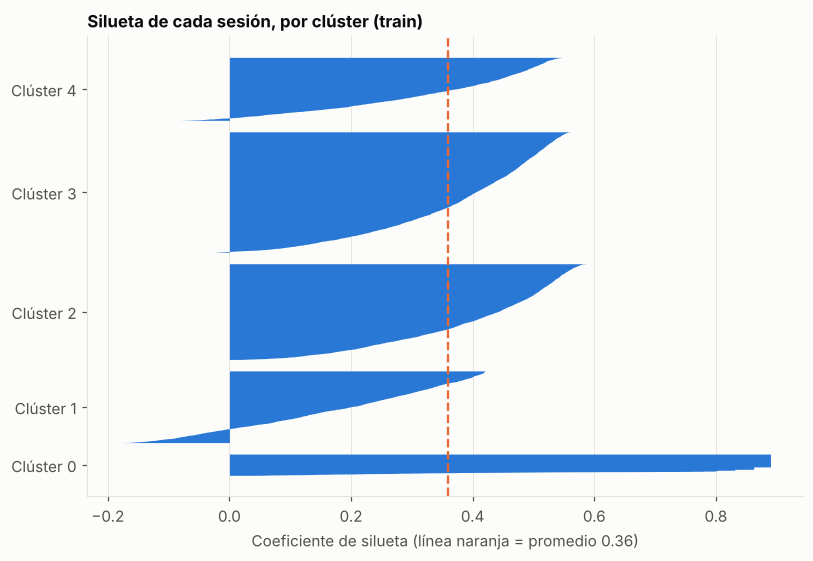

In [15]:
# Silueta por clúster (train)
sil_i = silhouette_samples(X_train, lab_train)

fig, ax = plt.subplots(figsize=(7.5, 5.2))
y = 0
marcas = []
for c in range(K_FINAL):
    v = np.sort(sil_i[lab_train == c])
    ax.fill_betweenx(np.arange(y, y + len(v)), 0, v, color=C["azul"], linewidth=0)
    marcas.append(y + len(v) / 2)
    y += len(v) + 300          # espacio entre clústeres
ax.axvline(sil_train, color=C["naranja"], linestyle="--", linewidth=1.5)
ax.set_yticks(marcas, [f"Clúster {c}" for c in range(K_FINAL)])
ax.set_xlabel(f"Coeficiente de silueta (línea naranja = promedio {sil_train:.2f})")
ax.set_title("Silueta de cada sesión, por clúster (train)")
ax.grid(axis="y", visible=False)
plt.tight_layout()
guardar("04_silueta_por_cluster.png")
plt.show()

pd.DataFrame({"silueta media": pd.Series(sil_i).groupby(lab_train).mean(),
              "% de sesiones con silueta < 0": pd.Series(sil_i < 0).groupby(lab_train).mean() * 100})

### 6.1 Estabilidad y sensibilidad

- **Estabilidad entre semillas**: se vuelve a entrenar el modelo 10 veces con semillas distintas y se compara cada resultado con el modelo final usando el índice de Rand ajustado (ARI; 1 = grupos idénticos, 0 = azar).
- **Sensibilidad a la redundancia**: se vuelve a agrupar quitando `BounceRates` (r = 0.90 con `ExitRates`) y `ProductRelated` (r = 0.85 con su duración), y se compara con el modelo final.

In [16]:
# Estabilidad entre semillas
ari_semillas = []
for s in range(10):
    kms = KMeans(K_FINAL, n_init=N_INIT, random_state=100 + s).fit(X_train)
    ari_semillas.append(adjusted_rand_score(lab_train, kms.labels_))
print(f"ARI entre semillas (10 corridas): mín = {min(ari_semillas):.3f} | media = {np.mean(ari_semillas):.3f} | máx = {max(ari_semillas):.3f}")

# Sensibilidad: sin las variables más redundantes
COLS_REDUCIDO = ["Administrative_Duration", "Informational_Duration", "ProductRelated_Duration", "ExitRates"]
sc_red = StandardScaler().fit(np.log1p(train[COLS_REDUCIDO]))
X_red = sc_red.transform(np.log1p(train[COLS_REDUCIDO]))
km_red = KMeans(K_FINAL, n_init=N_INIT, random_state=RANDOM_STATE).fit(X_red)
print(f"ARI entre el modelo final y el modelo con 4 variables: {adjusted_rand_score(lab_train, km_red.labels_):.3f}")

ARI entre semillas (10 corridas): mín = 0.994 | media = 0.997 | máx = 0.999
ARI entre el modelo final y el modelo con 4 variables: 0.816


## 7. Visualización en 2D (PCA)

Las sesiones viven en 6 dimensiones. Para verlas se proyectan a 2 componentes principales (PCA ajustado con `train`). Es solo una vista: la agrupación se hizo con las 6 variables. Para no tener que distinguir cinco colores, hay un panel por clúster: el clúster resaltado en azul y el resto en gris. Todos los paneles comparten los mismos ejes.

In [17]:
pca = PCA(n_components=6).fit(X_train)
Z_train = pca.transform(X_train)[:, :2]
var_exp = pca.explained_variance_ratio_
print(f"Varianza explicada: PC1 = {var_exp[0]*100:.1f} % | PC2 = {var_exp[1]*100:.1f} % | juntas = {var_exp[:2].sum()*100:.1f} %")

cargas = pd.DataFrame(pca.components_[:2].T, index=COLS_CLUSTER, columns=["PC1", "PC2"])
cargas

Varianza explicada: PC1 = 58.3 % | PC2 = 18.0 % | juntas = 76.3 %


,PC1,PC2
Administrative_Duration,0.314,0.415
Informational_Duration,0.227,0.727
ProductRelated_Duration,0.489,-0.065
ProductRelated,0.444,0.147
BounceRates,-0.431,0.425
ExitRates,-0.478,0.305


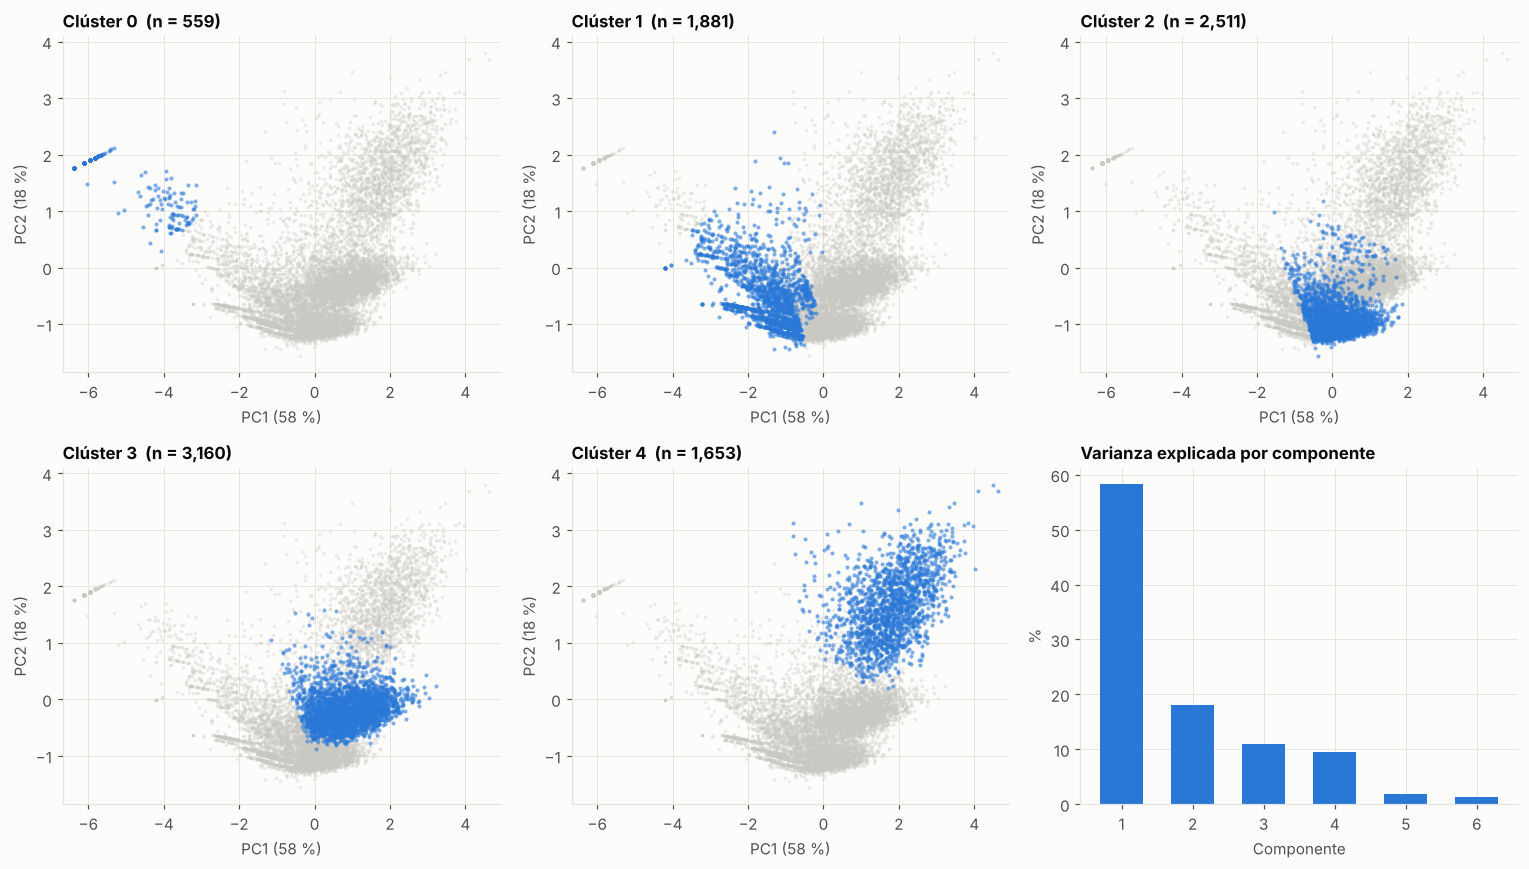

In [18]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
xl = (Z_train[:, 0].min() - 0.3, Z_train[:, 0].max() + 0.3)
yl = (Z_train[:, 1].min() - 0.3, Z_train[:, 1].max() + 0.3)
for c, ax in zip(range(K_FINAL), axes.ravel()):
    m = lab_train == c
    ax.scatter(Z_train[~m, 0], Z_train[~m, 1], s=5, color=C["gris"], alpha=0.35, linewidths=0)
    ax.scatter(Z_train[m, 0], Z_train[m, 1], s=7, color=C["azul"], alpha=0.6, linewidths=0)
    ax.set_title(f"Clúster {c}  (n = {m.sum():,})")
    ax.set_xlim(xl); ax.set_ylim(yl)
    ax.set_xlabel(f"PC1 ({var_exp[0]*100:.0f} %)")
    ax.set_ylabel(f"PC2 ({var_exp[1]*100:.0f} %)")
# último panel: varianza explicada por componente
ax = axes.ravel()[K_FINAL]
ax.bar(range(1, 7), var_exp * 100, color=C["azul"], width=0.6)
ax.set_title("Varianza explicada por componente")
ax.set_xlabel("Componente")
ax.set_ylabel("%")
ax.set_xticks(range(1, 7))
plt.tight_layout()
guardar("04_pca_clusteres.png")
plt.show()

## 8. Interpretación de los clústeres

Para describir, las 12,205 sesiones quedan asignadas a un clúster (las de `train` por el entrenamiento y las de `test` por el modelo ya entrenado). Aquí sí se usan `Revenue`, `PageValues` y las variables categóricas, que no entraron al modelo.

In [19]:
g = df_cl.groupby("cluster")
perfil = pd.DataFrame({
    "Sesiones": g.size(),
    "% del total": g.size() / len(df_cl) * 100,
    "Páginas de producto (mediana)": g["ProductRelated"].median(),
    "Dur. productos, s (mediana)": g["ProductRelated_Duration"].median(),
    "Dur. administrativas, s (mediana)": g["Administrative_Duration"].median(),
    "Dur. informativas, s (mediana)": g["Informational_Duration"].median(),
    "% con tiempo informativo > 0": g["Informational_Duration"].apply(lambda s: (s > 0).mean() * 100),
    "BounceRates (media)": g["BounceRates"].mean(),
    "ExitRates (media)": g["ExitRates"].mean(),
    "PageValues (media)": g["PageValues"].mean(),
    "Tasa de compra (%)": g["Revenue"].mean() * 100,
    "% visitantes nuevos": g["VisitorType"].apply(lambda s: (s == "New_Visitor").mean() * 100),
    "% visitantes recurrentes": g["VisitorType"].apply(lambda s: (s == "Returning_Visitor").mean() * 100),
    "% fin de semana": g["Weekend"].mean() * 100,
})
perfil.T

cluster,0,1,2,3,4
Sesiones,693.000,"2,344.000","3,149.000","3,955.000","2,064.000"
% del total,5.678,19.205,25.801,32.405,16.911
Páginas de producto (mediana),1.000,5.000,20.000,25.000,45.000
"Dur. productos, s (mediana)",0.000,95.050,710.000,851.250,"1,740.251"
"Dur. administrativas, s (mediana)",0.000,0.000,0.000,86.000,115.000
"Dur. informativas, s (mediana)",0.000,0.000,0.000,0.000,99.800
% con tiempo informativo > 0,0.433,2.346,4.922,3.236,100.000
BounceRates (media),0.188,0.022,0.009,0.006,0.007
ExitRates (media),0.193,0.068,0.028,0.021,0.021
PageValues (media),0.000,1.104,5.780,8.499,8.824


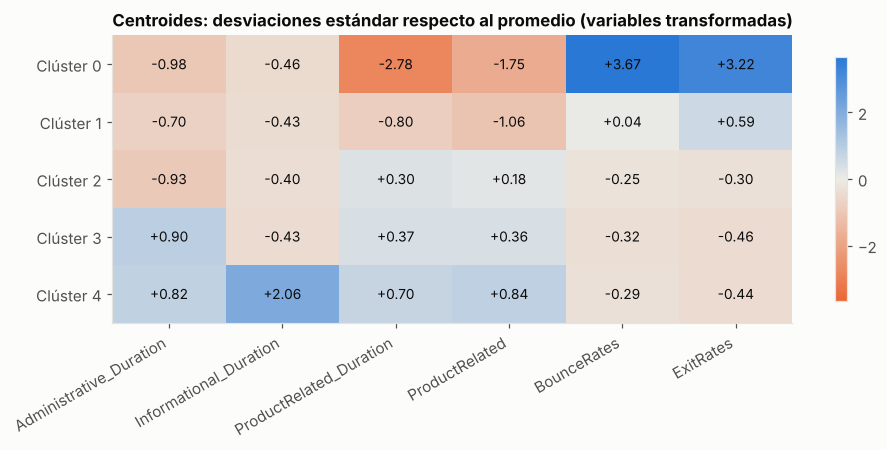

In [20]:
# Centroides en unidades estándar (espacio de entrenamiento): qué tan arriba o abajo del promedio está cada clúster
cent = pd.DataFrame(centros, columns=COLS_CLUSTER)

fig, ax = plt.subplots(figsize=(9, 4.2))
lim = np.abs(cent.values).max()
im = ax.imshow(cent.values, cmap=CMAP_DIV, vmin=-lim, vmax=lim, aspect="auto")
ax.grid(False)
ax.set_xticks(range(len(COLS_CLUSTER)), COLS_CLUSTER, rotation=30, ha="right")
ax.set_yticks(range(K_FINAL), [f"Clúster {c}" for c in range(K_FINAL)])
for i in range(K_FINAL):
    for j in range(len(COLS_CLUSTER)):
        ax.text(j, i, f"{cent.iloc[i, j]:+.2f}", ha="center", va="center", color=C["tinta"], fontsize=9)
ax.set_title("Centroides: desviaciones estándar respecto al promedio (variables transformadas)")
fig.colorbar(im, ax=ax, shrink=0.85)
plt.tight_layout()
guardar("04_centroides.png")
plt.show()

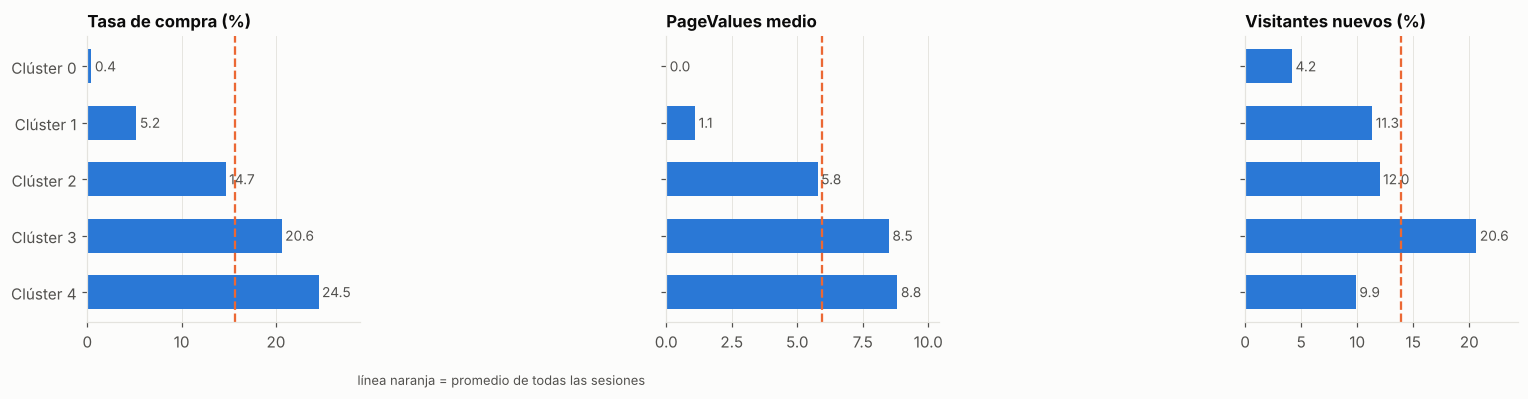

In [21]:
# Resultado de negocio por clúster (se usa lo que NO entró al modelo)
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
etiquetas = [f"Clúster {c}" for c in range(K_FINAL)]
medidas = [("Tasa de compra (%)", "Tasa de compra (%)", df_cl["Revenue"].mean() * 100),
           ("PageValues (media)", "PageValues medio", df_cl["PageValues"].mean()),
           ("% visitantes nuevos", "Visitantes nuevos (%)", (df_cl["VisitorType"] == "New_Visitor").mean() * 100)]
for ax, (col, titulo, global_) in zip(axes, medidas):
    vals = perfil[col].values
    ax.barh(range(K_FINAL), vals, color=C["azul"], height=0.6)
    ax.axvline(global_, color=C["naranja"], linestyle="--", linewidth=1.5)
    for i, v in enumerate(vals):
        ax.text(v + max(vals) * 0.015, i, f"{v:.1f}", va="center", fontsize=9, color=C["tinta2"])
    ax.set_title(titulo)
    ax.set_xlim(0, max(vals) * 1.18)
    ax.grid(axis="y", visible=False)
axes[0].set_yticks(range(K_FINAL), etiquetas)
axes[0].invert_yaxis()
axes[0].text(0.99, -0.22, "línea naranja = promedio de todas las sesiones", transform=axes[0].transAxes,
             ha="left", fontsize=8.5, color=C["tinta2"])
plt.tight_layout()
guardar("04_resultado_por_cluster.png")
plt.show()

In [22]:
# ¿Está la compra relacionada con el clúster? Prueba chi-cuadrada y V de Cramér
tabla = pd.crosstab(df_cl["cluster"], df_cl["Revenue"])
chi2, p, gl, _ = chi2_contingency(tabla)
v_cramer = np.sqrt(chi2 / (tabla.values.sum() * (min(tabla.shape) - 1)))
print(f"chi2 = {chi2:,.1f} | gl = {gl} | p = {p:.3g} | V de Cramér = {v_cramer:.3f}")
tabla

chi2 = 514.5 | gl = 4 | p = 4.82e-110 | V de Cramér = 0.205


Revenue,0,1
cluster,,
0,690,3
1,2222,122
2,2687,462
3,3140,815
4,1558,506


Month,Feb,Mar,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
cluster,,,,,,,,,,
0,4.900,13.400,34.200,4.300,3.300,2.600,1.300,1.400,22.100,12.400
1,2.600,19.500,30.200,2.700,3.500,2.400,2.800,3.400,18.500,14.200
2,1.900,14.700,29.300,2.200,3.100,2.500,2.700,2.300,26.500,14.600
3,0.500,14.400,24.200,1.800,3.900,4.900,5.300,6.900,24.000,14.000
4,0.300,13.400,24.400,2.400,3.600,4.100,3.800,5.400,29.500,13.100


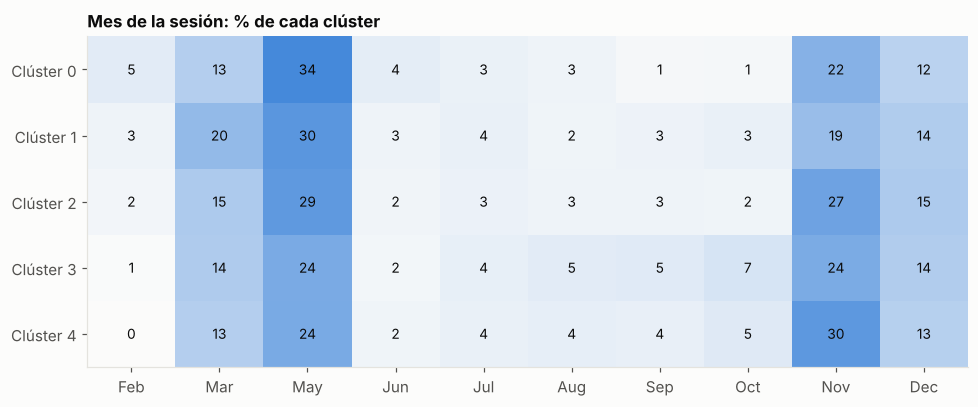

In [23]:
# Distribución por mes dentro de cada clúster (% de cada clúster)
meses = [m for m in ["Feb", "Mar", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"] if m in df_cl["Month"].unique()]
mes_pct = pd.crosstab(df_cl["cluster"], df_cl["Month"], normalize="index")[meses] * 100

fig, ax = plt.subplots(figsize=(9, 3.8))
im = ax.imshow(mes_pct.values, cmap=CMAP_SEC, aspect="auto", vmin=0, vmax=mes_pct.values.max() * 1.15)
ax.grid(False)
ax.set_xticks(range(len(meses)), meses)
ax.set_yticks(range(K_FINAL), [f"Clúster {c}" for c in range(K_FINAL)])
for i in range(K_FINAL):
    for j in range(len(meses)):
        ax.text(j, i, f"{mes_pct.iloc[i, j]:.0f}", ha="center", va="center", color=C["tinta"], fontsize=9)
ax.set_title("Mes de la sesión: % de cada clúster")
plt.tight_layout()
guardar("04_mes_por_cluster.png")
plt.show()
mes_pct.round(1)

### 8.1 Nombres de los clústeres

Con base en la tabla de perfiles (los clústeres están ordenados por tiempo total en el sitio):

| Clúster | Nombre sugerido | Sesiones | Qué lo define | Tasa de compra |
|---|---|---|---|---|
| 0 | Rebote inmediato | 5.7 % | 1 página, 0 segundos, rebote y salida ≈ 0.19, `PageValues` = 0 | 0.4 % |
| 1 | Visitas cortas | 19.2 % | ~5 páginas de producto, ~95 s, salida más alta de los activos (0.07) | 5.2 % |
| 2 | Navegación de producto | 25.8 % | ~20 páginas y ~710 s en productos, casi sin páginas administrativas | 14.7 % |
| 3 | Navegación con gestión de cuenta | 32.4 % | ~25 páginas de producto (~850 s) más ~86 s en páginas administrativas; el grupo con más visitantes nuevos (20.6 %) | 20.6 % |
| 4 | Exploración profunda | 16.9 % | ~45 páginas de producto (~1,740 s), páginas administrativas e informativas (el 100 % visita las informativas) | 24.5 % |

Los nombres son una propuesta: se pueden ajustar al redactar el informe. Si se cambia `random_state` o la versión de scikit-learn, hay que revisar que la tabla de perfiles (arriba) siga mostrando el mismo orden.

## 9. Hallazgos, limitaciones y exportación

### Hallazgos

1. **Cinco perfiles de navegación bien diferenciados**, con una gradación clara: a más páginas y más tiempo en el sitio, más probabilidad de compra (de 0.4 % en el clúster 0 a 24.5 % en el 4; promedio general 15.6 %).
2. **La relación con la compra es real pero moderada**: la prueba chi-cuadrada rechaza la independencia entre clúster y `Revenue` (V de Cramér = 0.21), aunque `Revenue` **no** se usó para agrupar. Eso indica que los grupos capturan comportamiento relevante para el negocio.
3. **El clúster 0 (rebote inmediato) casi no compra** (3 compras en 693 sesiones) y son casi todos visitantes recurrentes (94 %).
4. **El clúster 3 es el que más visitantes nuevos concentra** (20.6 % frente a 4 a 12 % en los demás) y tiene una tasa de compra alta (20.6 %); sus sesiones incluyen páginas administrativas.
5. **El clúster 4 tiene la mayor tasa de compra (24.5 %)** con la exploración más profunda: es el único donde todas las sesiones visitan páginas informativas.
6. El mes aporta poco a la separación. Los clústeres 3 y 4 tienen algo más de sesiones de agosto a octubre (17 % y 13 %) que el 0 (5 %), y el 2 y el 4 algo más de noviembre.

### Calidad y estabilidad

- Silueta global de 0.36 en `train` y 0.36 en `test`; Davies-Bouldin 0.94 en ambos: la estructura es **moderada**, no hay grupos totalmente aislados.
- **Muy estable**: ARI entre semillas de 0.99 (mín. 0.994). Las sesiones de `test` se reparten en proporciones casi idénticas a las de `train`.
- Al quitar las variables más redundantes (`BounceRates`, `ProductRelated`) la agrupación se conserva en buena medida (ARI = 0.82).

### Limitaciones

- La silueta de 0.36 indica que el comportamiento de navegación es más un **continuo** que grupos separados; las fronteras entre clústeres vecinos son difusas, sobre todo en el clúster 1 (silueta media de 0.18, con 19 % de sus sesiones mejor ubicadas en otro clúster).
- K-Means asume grupos compactos y de forma esférica, es sensible a la transformación y al escalado, y requiere fijar k; la elección de k = 5 es de criterio (k = 4 es casi igual de buena según las métricas).
- Las tasas (`BounceRates`, `ExitRates`) siguen asimétricas tras `log1p`.
- Los datos son de una sola tienda, cubren 10 meses (no hay enero ni abril) y las sesiones no tienen identificador de usuario. La relación entre clúster y compra es una **asociación, no causalidad**.

### Posibles aplicaciones

- Distinguir **rebotes** (clúster 0) de visitas con intención y revisar sus páginas de entrada.
- **Retargeting y ofertas** para los clústeres 2 y 3, que ya navegan productos pero compran menos que el 4.
- Revisar la experiencia de **visitantes nuevos** (clúster 3), donde se concentra la gestión de cuenta.
- Usar el clúster como variable adicional en los modelos de clasificación (`data/clusters_asignados.csv`).

In [24]:
os.makedirs("data", exist_ok=True)
perfil.T.to_csv("data/perfil_clusters.csv")
df_cl[["conjunto", "cluster"]].to_csv("data/clusters_asignados.csv", index_label="indice")
print("Guardado: data/perfil_clusters.csv y data/clusters_asignados.csv")
print("Gráficas en:", sorted(os.listdir(DIR_FIG)))

Guardado: data/perfil_clusters.csv y data/clusters_asignados.csv
Gráficas en: ['04_centroides.png', '04_correlacion_variables.png', '04_efecto_log1p.png', '04_mes_por_cluster.png', '04_pca_clusteres.png', '04_resultado_por_cluster.png', '04_seleccion_k.png', '04_silueta_por_cluster.png']
